In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

from google.colab import files

# Upload cleaned dataset
uploaded = files.upload()

# Load the CSV file
df = pd.read_csv("titanic_cleaned.csv")

# Display first five rows
df.head()


Saving titanic_cleaned.csv to titanic_cleaned.csv


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,C,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,C,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,C,Southampton,no,True


In [3]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()


Dataset shape: (784, 15)

Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Missing values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 784 entries, 0 to 783
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     784 non-null    int64  
 1   pclass       784 non-null    int64  
 2   sex          784 non-null    object 
 3   age          784 non-null    float64
 4   sibsp        784 non-null    int64  
 5   parch        784 non-null    int64  
 6   fare         784 non-null    float64
 7   embarked     784 no

In [4]:

# Summary statistics for numerical columns
print("Numerical Summary:")
display(df.describe().T)

# Summary of categorical columns
print("\nCategorical Summary:")
display(df.describe(include="object").T)


Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
survived,784.0,0.411990,0.492507,0.00,0.00,0.00,1.00000,1.0000
pclass,784.0,2.243622,0.855056,1.00,1.00,3.00,3.00000,3.0000
age,784.0,29.650408,13.734925,0.42,22.00,28.25,36.00000,80.0000
sibsp,784.0,0.522959,0.986231,0.00,0.00,0.00,1.00000,8.0000
parch,784.0,0.415816,0.836922,0.00,0.00,0.00,1.00000,6.0000
fare,784.0,34.711740,52.160151,0.00,8.05,15.90,34.10935,512.3292



Categorical Summary:


,count,unique,top,freq
sex,784,2,male,491
embarked,784,3,S,570
class,784,3,Third,405
who,784,3,man,451
deck,784,7,C,641
embark_town,784,3,Southampton,570
alive,784,2,no,461


In [5]:

# 1. Total passengers
print("Total passengers:", len(df))

# 2. Overall survival rate
survival_rate = df["survived"].mean() * 100
print(f"Overall survival rate: {survival_rate:.2f}%")

# 3. Survival rate by gender
print("\nSurvival rate by gender (%):")
display(
    df.groupby("sex")["survived"]
      .mean()
      .mul(100)
      .round(2)
)

# 4. Survival rate by passenger class
print("\nSurvival rate by passenger class (%):")
display(
    df.groupby("pclass")["survived"]
      .mean()
      .mul(100)
      .round(2)
)

# 5. Average age and fare
print("\nAverage age:", round(df["age"].mean(), 2))
print("Average fare:", round(df["fare"].mean(), 2))


Total passengers: 784
Overall survival rate: 41.20%

Survival rate by gender (%):


,survived
sex,
female,74.06
male,21.59



Survival rate by passenger class (%):


,survived
pclass,
1,63.08
2,50.91
3,25.68



Average age: 29.65
Average fare: 34.71


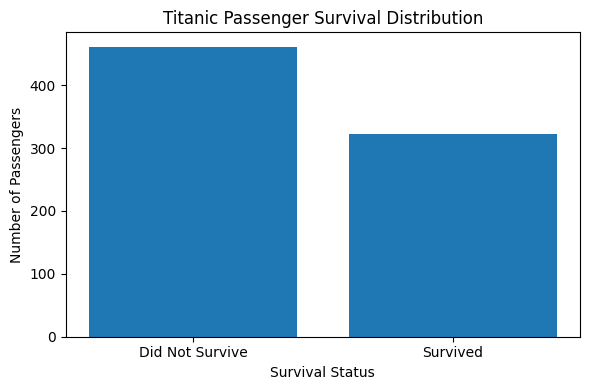

In [6]:

# Count passengers who survived and did not survive
survival_counts = df["survived"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    ["Did Not Survive", "Survived"],
    survival_counts.values
)
plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


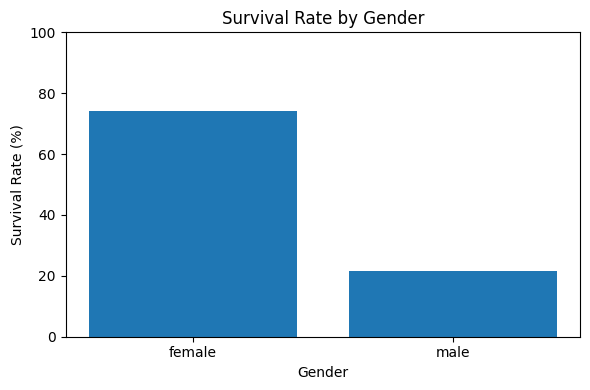

In [7]:

gender_survival = (
    df.groupby("sex")["survived"].mean() * 100
)

plt.figure(figsize=(6, 4))
plt.bar(gender_survival.index, gender_survival.values)
plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


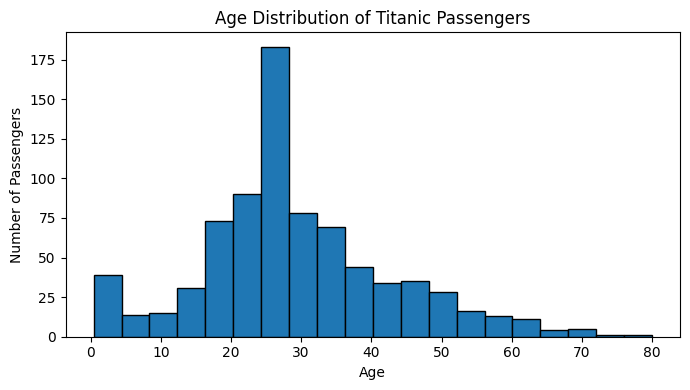

In [8]:

plt.figure(figsize=(7, 4))
plt.hist(df["age"].dropna(), bins=20, edgecolor="black")
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()


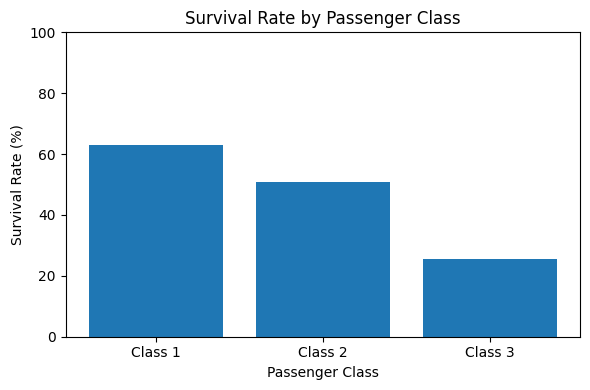

In [9]:

class_survival = (
    df.groupby("pclass")["survived"].mean() * 100
)

plt.figure(figsize=(6, 4))
plt.bar(class_survival.index.astype(str), class_survival.values)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks([0, 1, 2], ["Class 1", "Class 2", "Class 3"])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [10]:

# Function to detect outliers using the IQR method
def detect_outliers(data, column):
    values = data[column].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Number of outliers:", len(outliers))

    return outliers

age_outliers = detect_outliers(df, "age")
fare_outliers = detect_outliers(df, "fare")



Column: age
Lower bound: 1.0
Upper bound: 57.0
Number of outliers: 39

Column: fare
Lower bound: -31.04
Upper bound: 73.2
Number of outliers: 102


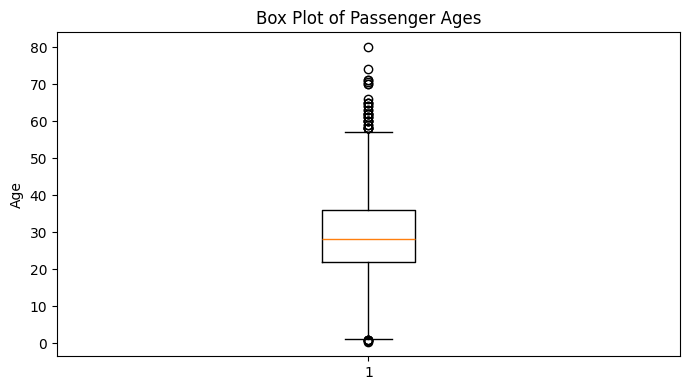

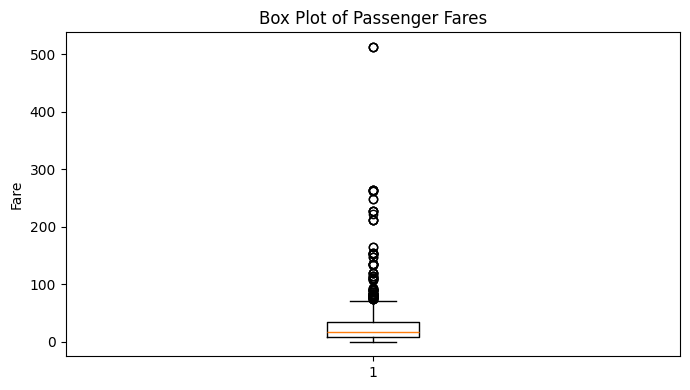

In [11]:

plt.figure(figsize=(7, 4))
plt.boxplot(df["age"].dropna())
plt.title("Box Plot of Passenger Ages")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.boxplot(df["fare"].dropna())
plt.title("Box Plot of Passenger Fares")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()


In [12]:

# Group ages into categories
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult",
            "Adult", "Senior"]
)

print("Survival rate by age group (%):")
display(
    (df.groupby("age_group", observed=False)["survived"]
       .mean() * 100).round(2)
)

# Inspect the 10 highest fares
print("\n10 highest ticket fares:")
display(
    df.nlargest(10, "fare")[["pclass", "sex", "age", "fare", "survived"]]
)


Survival rate by age group (%):


,survived
age_group,
Child,57.35
Teenager,44.78
Young Adult,39.54
Adult,40.10
Senior,22.73



10 highest ticket fares:


,pclass,sex,age,fare,survived
243,1,female,35.0,512.3292,1
600,1,male,36.0,512.3292,1
652,1,male,35.0,512.3292,1
27,1,male,19.0,263.0000,0
84,1,female,23.0,263.0000,1
317,1,female,24.0,263.0000,1
398,1,male,64.0,263.0000,0
291,1,female,18.0,262.3750,1
655,1,female,21.0,262.3750,1
112,1,male,24.0,247.5208,0


In [14]:

# Step 8A: Generate an EDA report from your actual results

total = len(df)
survivors = int(df["survived"].sum())
non_survivors = total - survivors
survival_pct = df["survived"].mean() * 100

gender_rates = (df.groupby("sex")["survived"].mean() * 100).round(2)
class_rates = (df.groupby("pclass")["survived"].mean() * 100).round(2)

age_median = df["age"].median()
age_mean = df["age"].mean()
fare_mean = df["fare"].mean()

# Calculate outliers using the IQR method
def count_iqr_outliers(series):
    values = series.dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return int(((values < lower) | (values > upper)).sum())

age_outlier_count = count_iqr_outliers(df["age"])
fare_outlier_count = count_iqr_outliers(df["fare"])

highest_fare = df["fare"].max()

# Build the report
report = f"""
TITANIC PASSENGER SURVIVAL
EXPLORATORY DATA ANALYSIS (EDA) REPORT

1. OBJECTIVE
Analyze Titanic passenger data to understand survival patterns,
passenger characteristics, and unusual values.

2. DATASET OVERVIEW
Total records analyzed: {total}
Number of columns: {df.shape[1]}
Average passenger age: {age_mean:.2f}
Median passenger age: {age_median:.2f}
Average ticket fare: {fare_mean:.2f}

3. KEY FINDINGS
Passengers who survived: {survivors}
Passengers who did not survive: {non_survivors}
Overall survival rate: {survival_pct:.2f}%

Survival rate by gender:
{gender_rates.to_string()}

Survival rate by passenger class:
{class_rates.to_string()}

4. OUTLIER ANALYSIS
Potential age outliers (IQR method): {age_outlier_count}
Potential fare outliers (IQR method): {fare_outlier_count}
Highest ticket fare: {highest_fare:.2f}

Outliers are potential unusual observations and are not
automatically errors. They should be investigated in context.

5. VISUALIZATIONS
The analysis includes:
- Passenger survival distribution
- Survival rate by gender
- Passenger age distribution
- Survival rate by passenger class
- Box plots for age and fare

6. CONCLUSION
The analysis summarizes survival outcomes and compares survival
rates across gender and passenger class. Descriptive statistics
and box plots help identify distributions and potential outliers.
These results show associations and do not establish causation.

7. TOOLS USED
Python, Pandas, NumPy, Matplotlib
"""

print(report)

with open("CODSOFT_TASK2_EDA_Report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("\nReport saved as CODSOFT_TASK2_EDA_Report.txt")



TITANIC PASSENGER SURVIVAL
EXPLORATORY DATA ANALYSIS (EDA) REPORT

1. OBJECTIVE
Analyze Titanic passenger data to understand survival patterns,
passenger characteristics, and unusual values.

2. DATASET OVERVIEW
Total records analyzed: 784
Number of columns: 16
Average passenger age: 29.65
Median passenger age: 28.25
Average ticket fare: 34.71

3. KEY FINDINGS
Passengers who survived: 323
Passengers who did not survive: 461
Overall survival rate: 41.20%

Survival rate by gender:
sex
female    74.06
male      21.59

Survival rate by passenger class:
pclass
1    63.08
2    50.91
3    25.68

4. OUTLIER ANALYSIS
Potential age outliers (IQR method): 39
Potential fare outliers (IQR method): 102
Highest ticket fare: 512.33

Outliers are potential unusual observations and are not
automatically errors. They should be investigated in context.

5. VISUALIZATIONS
The analysis includes:
- Passenger survival distribution
- Survival rate by gender
- Passenger age distribution
- Survival rate by pass

In [15]:

from google.colab import files

files.download("CODSOFT_TASK2_EDA_Report.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>